# Getting started: predicting gene expression from genomic and experimental context

This notebook provides a **minimal end-to-end pipeline** for the gene-expression challenge.

## Data

Each observation corresponds to a **gene × sample** pair, and the target `counts` is the observed RNA-seq read count for that gene under that experimental condition.

The information describing each observation comes from three sources:

1. **Gene information (`train_data.tsv` / `test_data.tsv`)**  
   These tables contain one row per gene × sample observation. For the genomic part, they contain mainly the coordinates of the measured feature (`Chr`, `Start`, `End`, `Strand`, etc.), rather than the DNA sequence itself.

2. **Genome (`genomes/*.gb`)**  
   The GenBank files contain the actual genome sequence. Using the coordinates above, we can retrieve DNA regions associated with each gene. In this baseline, we use the 200 bp upstream region as a simple approximation of the promoter and derive a few basic sequence features from it.

3. **Sample metadata (`samples.tsv`)**  
   This table describes the experimental conditions associated with each sample, such as growth medium, culture type, pH, temperature, and growth rate. It is linked to the main tables through `run_accession`.

For this introductory example, we use only **E. coli**, because the current data release provides all three input sources for this organism.

## Baseline and metric

The final challenge will ask participants to predict two parameters, **μ and σ**, describing the distribution of RNA-seq counts. The predictions will be evaluated using a Negative Binomial likelihood-based score. The exact parameterization and loss are still being finalized.

For this notebook, we therefore use a temporary setup that preserves the expected two-output structure:

- **Model:** a simple MLP combining genome-derived features, gene/sample covariates, and experimental metadata to predict `mu` and `sigma`.
- **Temporary loss:** `L = L_mu + 0.1 L_sigma`. `mu` is trained to predict the transformed count target, while `sigma` is trained to approximate the magnitude of the residual `|target - mu|`.

In other words, if `mu` is close to the true value, the desired `sigma` is small; if `mu` is far from the true value, the desired `sigma` is larger. This loosely reflects the intended role of the two outputs in the final Negative Binomial model, where `mu` represents the expected count and `sigma` will represent some form of dispersion or uncertainty.

This is only a convenient placeholder to make both outputs trainable. It does **not** mathematically approximate the official Negative Binomial loss, and the meaning of `sigma` here is not necessarily the same as the final Negative Binomial `sigma`.

> **Important:** This pipeline is intentionally simple. Its purpose is to illustrate how the different data sources can be combined in an end-to-end ML pipeline, not to provide a biologically optimized model.

### TODO for Ernest

1. Replace `placeholder_loss` with the final Negative Binomial loss / scoring function and clarify the exact definitions of `mu` and `sigma`.
2. Propose a stronger biological/ML baseline if desired.

3. For the final challenge data, I suggest keeping the following columns outside the participant feature matrix `X`:

- **`condition_split`, `feature_split`**: these are used to construct the train/test split. They should not be used as predictive features, as they expose information about the evaluation design.
- **`gene_weight`, `condition_weight`**: these are intended for weighting the training/evaluation loss rather than as predictive features.

Columns such as `reference`, `Geneid`, `Chr`, `Start`, `End`, `Strand`, and `run_accession` can remain available because they are needed to retrieve genomic information or sample metadata, even if they are not necessarily used directly as predictive features.

### Operational TODO before integration into Codabench

This notebook is currently a self-contained prototype: data preparation, feature construction, model training and evaluation are kept directly in the notebook to make the full pipeline easy to inspect and modify.

Once the dataset format, baseline and final scoring function are validated, the pipeline still needs to be integrated into the Codabench starting-kit structure:

- move the finalized data loading / preparation logic to ingestion_program/ingestion.py;
- move the finalized challenge metric to scoring_program/scoring.py;
- expose the baseline model through solution/submission.py;
- adapt the notebook to use these functions, following the standard starting-kit template;
- prepare the final participant-facing train/test data and verify the complete local submission → ingestion → scoring pipeline.

For now, these steps are intentionally postponed so that the data processing and modelling choices remain explicit and easy to review.

## 1. Load and inspect the data

We start by loading the provided training and test tables. Both contain one row per **(gene × sample)** observation. In this local development version, both files contain `counts`; in the final challenge, test labels will be hidden from participants.


In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

train_all = pd.read_csv("train_data.tsv", sep="\t")
test_all = pd.read_csv("test_data.tsv", sep="\t")

print("Train shape:", train_all.shape)
print("Test shape:", test_all.shape)

train_all.head()


Train shape: (1855356, 15)
Test shape: (18708, 15)


,reference,Geneid,Chr,Start,End,Strand,Length,run_accession,condition_split,feature_split,log_length_ratio,log_size_factor,gene_weight,condition_weight,counts
0,GCF_000005845.2,cds-NP_414542.1,NC_000913.3,190,255,+,66,SRR1168135,train,train,-11.032239,16.338593,1.0,1.0,417
1,GCF_000005845.2,cds-NP_414543.1,NC_000913.3,337,2799,+,2463,SRR1168135,train,train,-7.412758,16.338593,1.0,1.0,77255
2,GCF_000005845.2,cds-NP_414544.1,NC_000913.3,2801,3733,+,933,SRR1168135,train,train,-8.383488,16.338593,1.0,1.0,30353
3,GCF_000005845.2,cds-NP_414545.1,NC_000913.3,3734,5020,+,1287,SRR1168135,train,test,-8.061824,16.338593,1.0,1.0,19338
4,GCF_000005845.2,cds-NP_414546.1,NC_000913.3,5234,5530,+,297,SRR1168135,train,train,-9.528161,16.338593,1.0,1.0,303


Columns:
['reference', 'Geneid', 'Chr', 'Start', 'End', 'Strand', 'Length', 'run_accession', 'condition_split', 'feature_split', 'log_length_ratio', 'log_size_factor', 'gene_weight', 'condition_weight', 'counts']


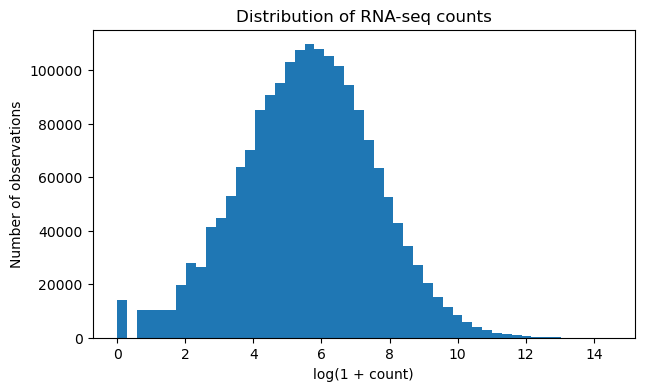

In [2]:
print("Columns:")
print(train_all.columns.tolist())
# would "remove" 'condition_split', 'feature_split', 'gene_weight', 'condition_weight'

plt.figure(figsize=(7, 4))
plt.hist(np.log1p(train_all["counts"]), bins=50)
plt.xlabel("log(1 + count)")
plt.ylabel("Number of observations")
plt.title("Distribution of RNA-seq counts")
plt.show()


## 2. Focus on E. coli

The complete dataset contains multiple organisms. For this tutorial, we keep only the E. coli observations.

The `reference` column identifies the reference genome used for quantification. For E. coli MG1655, the reference is `GCF_000005845.2`.


In [3]:
ECOLI_REFERENCE = "GCF_000005845.2"

train = train_all[
    train_all["reference"] == ECOLI_REFERENCE
].copy()

test = test_all[
    test_all["reference"] == ECOLI_REFERENCE
].copy()

print("E. coli train shape:", train.shape)
print("E. coli test shape:", test.shape)
print("Training genes:", train["Geneid"].nunique())
print("Training samples:", train["run_accession"].nunique())


E. coli train shape: (376968, 15)
E. coli test shape: (3888, 15)
Training genes: 4534
Training samples: 84


## 3. Understand the challenge split

The challenge is designed to test generalization to **new genes and new experimental conditions at the same time**.

Two columns describe how the original gene × condition matrix was split:

- `feature_split`: whether the **gene** belongs to the train or test gene set
- `condition_split`: whether the **sample/condition** belongs to the train or test condition set

`train_data.tsv` contains observations for which **at least one** of these two dimensions belongs to the training set. The held-out evaluation block in `test_data.tsv` contains observations for which:

```text
feature_split == "test"
AND
condition_split == "test"
```

Therefore, we use the provided `train_data.tsv` directly for fitting and `test_data.tsv` directly for evaluation. The split indicators themselves are **not used as model features**.


## 4. Build features from three input sources

Our simple baseline combines information about the gene, the experimental condition, and the genome sequence.


### 4.1 Experimental metadata from `samples.tsv`

`run_accession` in the main tables is a foreign key to `Run` in `samples.tsv`. We merge the metadata into both train and test using the same operation.

For this baseline, we will later use only a small subset of metadata fields. Participants may choose richer representations.


In [4]:
samples = pd.read_csv("samples.tsv", sep="\t")

train = train.merge(
    samples,
    left_on="run_accession",
    right_on="Run",
    how="left",
)

test = test.merge(
    samples,
    left_on="run_accession",
    right_on="Run",
    how="left",
)

print("Train metadata coverage:", train["Run"].notna().mean())
print("Test metadata coverage:", test["Run"].notna().mean())


Train metadata coverage: 1.0
Test metadata coverage: 1.0


### 4.2 Genome-derived promoter features

The E. coli genome is provided as a GenBank (.gb) file. You can think of this file as containing the organism's complete DNA sequence, together with annotations describing where genes are located.

In train_data.tsv and test_data.tsv, each gene is identified by genomic coordinates:

- Chr: which chromosome/sequence contains the gene;
- Start and End: where the gene is located in that sequence;
- Strand: the direction in which the gene is read (+ or -).

These coordinates describe the gene itself, but for this simple baseline we are particularly interested in the DNA immediately upstream of the gene, called here the promoter region. Promoters and other regulatory regions can influence how strongly a gene is transcribed and therefore can contain useful information for predicting RNA-seq counts:

In [5]:
#                         Start                  End
#                          ↓                     ↓
# Genome  ---- promoter ---|======= gene ========|------
#             ~200 bp
#             ↑
#        extracted here

For a gene on the + strand, "upstream" means the DNA before Start. For a gene on the - strand, the direction is reversed, so the upstream region lies after End in the stored genome coordinates and must be reverse-complemented.

As a deliberately simple modelling choice, we extract up to 200 base pairs (bp) upstream of each gene. We then convert this DNA string into numerical features by computing the proportion of A, C, G, and T, as well as the combined G+C proportion.

For example, a sequence such as AACGTGGC becomes approximately:
A = 0.25, C = 0.25, G = 0.375, T = 0.125, GC = 0.625
This is an intentionally crude representation: it captures the overall nucleotide composition but completely ignores the order of the bases. Two biologically different promoter sequences can therefore have identical features. It is used here only to demonstrate how genomic sequence can be converted into numerical ML inputs. Participants can explore richer representations such as k-mer frequencies or learned sequence representations.

Note also that this baseline extracts features from the upstream/promoter region, not from the gene DNA sequence itself. Using the gene sequence and other genomic annotations is another possible direction for improving the model.

In [6]:
# Run once if Biopython is not already installed:
# !pip install biopython

from Bio import SeqIO

genome_path = "genomes/GCA_000005845.2.gb"

records = {
    record.id: record
    for record in SeqIO.parse(genome_path, "genbank")
}

print("Genome records:", list(records.keys()))

Genome records: ['NC_000913.3']


In [7]:
records

{'NC_000913.3': SeqRecord(seq=Seq('AGCTTTTCATTCTGACTGCAACGGGCAATATGTCTCTGTGTGGATTAAAAAAAG...TTC'), id='NC_000913.3', name='NC_000913', description='Escherichia coli str. K-12 substr. MG1655, complete genome', dbxrefs=['BioProject:PRJNA57779', 'BioSample:SAMN02604091'])}

In [8]:
def extract_upstream_sequence(row, records, upstream=200):
    """
    Extract the DNA sequence immediately upstream of a gene.

    Parameters
    ----------
    row : pandas.Series
        One gene description containing the columns:
        `Chr`, `Start`, `End`, and `Strand`.

        Some genes may be represented by multiple genomic intervals,
        in which case these columns contain semicolon-separated values.

    records : dict
        Dictionary mapping chromosome/sequence IDs to Biopython
        SeqRecord objects loaded from the GenBank genome file.

    upstream : int, default=200
        Maximum number of base pairs to extract upstream of the gene.

    Returns
    -------
    str
        The upstream DNA sequence, oriented in the direction in which
        the gene is read.

    Notes
    -----
    For a '+' strand gene, the upstream region is located immediately
    before the gene's Start coordinate:

        ---- upstream ----|====== gene ======>
                          Start

    For a '-' strand gene, the gene is read in the opposite direction.
    Its upstream region is therefore located after its End coordinate
    in the stored genome sequence:

        <====== gene =====|---- upstream ----
                          End

    In this case, the extracted sequence is reverse-complemented so
    that both '+' and '-' strand sequences are returned in the
    gene's reading orientation.

    The coordinates in the input table are 1-based, whereas Python
    sequence slicing is 0-based.
    """

    chromosomes = str(row["Chr"]).split(";")
    starts = [int(x) for x in str(row["Start"]).split(";")]
    ends = [int(x) for x in str(row["End"]).split(";")]
    strands = str(row["Strand"]).split(";")

    # Intervals belonging to one feature are expected to be
    # on the same chromosome and strand in this dataset.
    chrom = chromosomes[0]
    strand = strands[0]

    seq = records[chrom].seq

    if strand == "+":
        gene_start = min(starts)

        promoter = seq[
            max(0, gene_start - 1 - upstream):
            gene_start - 1
        ]

    else:
        gene_end = max(ends)

        promoter = seq[
            gene_end:
            min(len(seq), gene_end + upstream)
        ].reverse_complement()

    return str(promoter)

In [9]:
def sequence_features(seq):
    """
    Convert a DNA sequence into simple numerical features.

    A DNA sequence is a string composed mainly of the four bases
    A, C, G, and T. Most standard ML models cannot directly use
    such a string as input, so we need to convert it into numbers.

    This simple baseline represents a sequence by:

    - the fraction of bases that are A;
    - the fraction that are C;
    - the fraction that are G;
    - the fraction that are T;
    - the GC content: fraction of bases that are G or C.

    For example:

        sequence = "AACGTGGC"

        A  = 2 / 8
        C  = 2 / 8
        G  = 3 / 8
        T  = 1 / 8
        GC = 5 / 8

    This representation is intentionally simple. It captures overall
    nucleotide composition but loses all information about the order
    of the bases. More advanced approaches could instead use k-mers,
    one-hot encoded sequences, CNNs, Transformers, or other learned
    sequence representations.

    Parameters
    ----------
    seq : str
        DNA sequence to summarize.

    Returns
    -------
    dict
        Numerical features describing the nucleotide composition
        of the sequence.
    """

    seq = seq.upper()
    n = max(len(seq), 1)

    return {
        "promoter_A": seq.count("A") / n,
        "promoter_C": seq.count("C") / n,
        "promoter_G": seq.count("G") / n,
        "promoter_T": seq.count("T") / n,
        "promoter_GC": (seq.count("G") + seq.count("C")) / n,
    }

In [11]:
gene_columns = ["Geneid", "Chr", "Start", "End", "Strand"]

genes = (
    pd.concat([
        train[gene_columns],
        test[gene_columns],
    ])
    .drop_duplicates("Geneid")
    .copy()
)

In [13]:
# Compute sequence features once per unique gene appearing in train or test.
gene_columns = ["Geneid", "Chr", "Start", "End", "Strand"]

genes = (
    pd.concat([
        train[gene_columns],
        test[gene_columns],
    ])
    .drop_duplicates("Geneid")
    .copy()
)

genes["promoter_sequence"] = genes.apply(
    extract_upstream_sequence,
    axis=1,
    records=records,
)

seq_features = pd.DataFrame(
    genes["promoter_sequence"].apply(sequence_features).tolist(),
    index=genes.index,
)

genes = pd.concat(
    [genes[["Geneid"]], seq_features],
    axis=1,
)

train = train.merge(genes, on="Geneid", how="left")
test = test.merge(genes, on="Geneid", how="left")

genes.head()


,Geneid,promoter_A,promoter_C,promoter_G,promoter_T,promoter_GC
0,cds-NP_414542.1,0.343915,0.185185,0.185185,0.285714,0.37037
1,cds-NP_414543.1,0.360000,0.280000,0.195000,0.165000,0.47500
2,cds-NP_414544.1,0.220000,0.240000,0.285000,0.255000,0.52500
3,cds-NP_414545.1,0.205000,0.270000,0.330000,0.195000,0.60000
4,cds-NP_414546.1,0.340000,0.180000,0.235000,0.245000,0.41500


### 4.3 Select the baseline features

The baseline deliberately keeps the representation small:

- basic gene/count-scale covariates;
- a few experimental metadata fields;
- simple nucleotide-composition summaries of the upstream sequence.

Identifiers and split indicators are not used as predictive features.


In [27]:
genome_features = [
    "promoter_A",
    "promoter_C",
    "promoter_G",
    "promoter_T",
    "promoter_GC",
]

numeric_features = [
    "Length",
    "log_length_ratio",
    "log_size_factor",
    "pH",
    "Temperature (C)",
    "Growth Rate (1/hr)",
] + genome_features

categorical_features = [
    "Base Media", # bacterial growth media
    "Culture Type", # describes how bacteria were cultured
]

features = numeric_features + categorical_features

X_train = train[features].copy()
X_test = test[features].copy()

y_train = train["counts"].to_numpy()
y_test = test["counts"].to_numpy()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Same feature columns:",
      X_train.columns.tolist() == X_test.columns.tolist())


X_train: (376968, 13)
X_test: (3888, 13)
Same feature columns: True


## 5. Preprocess the tabular features

Numeric variables are median-imputed and standardized. Categorical variables are imputed and one-hot encoded.

The preprocessor is **fitted only on the training data**, then applied unchanged to the test data.


In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
    )),
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features),
])

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

print("Processed X_train:", X_train.shape)
print("Processed X_test:", X_test.shape)


Processed X_train: (376968, 15)
Processed X_test: (3888, 15)


## 6. Minimal neural-network baseline


The final challenge model is expected to output two values, (mu, sigma), which will later parameterize the official Negative Binomial loss. Since that loss is not available yet, we use a temporary objective that preserves the same two-output model structure.

For this **temporary objective**:

mu is trained to predict the standardized log1p(count);
sigma is trained to approximate how large the prediction error of mu is for that observation.

In other words, if mu is close to the true value, the desired sigma is small; if mu is far from the true value, the desired sigma is larger. This loosely reflects the intended role of the two outputs in the final Negative Binomial loss, where mu represents the expected count and sigma will represent some form of dispersion or uncertainty.

This is only a convenient placeholder to make both outputs trainable, and the meaning of sigma here is not necessarily the same as the final Negative Binomial sigma.

In [29]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Counts are strongly right-skewed, so use log(1 + count).
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

# Standardize using training statistics only.
y_mean = y_train_log.mean()
y_std = y_train_log.std()

y_train_scaled = (y_train_log - y_mean) / y_std
y_test_scaled = (y_test_log - y_mean) / y_std

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

y_train_tensor = torch.tensor(
    y_train_scaled, dtype=torch.float32
).reshape(-1, 1)

y_test_tensor = torch.tensor(
    y_test_scaled, dtype=torch.float32
).reshape(-1, 1)


In [30]:
class CountModel(nn.Module):
    def __init__(self, n_features):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(n_features, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
        )

        self.output = nn.Linear(32, 2)

    def forward(self, x):
        h = self.network(x)
        mu, raw_sigma = self.output(h).chunk(2, dim=1)

        # Keep sigma positive.
        sigma = F.softplus(raw_sigma) + 1e-4

        return mu, sigma


def placeholder_loss(y, mu, sigma, eps=1e-4):
    """Temporary loss used only for this getting-started example."""

    # Main objective: predict the standardized log-count.
    mean_loss = F.smooth_l1_loss(mu, y)

    # Temporary auxiliary objective for sigma.
    residual = torch.abs(y - mu.detach()) + eps
    sigma_loss = F.smooth_l1_loss(
        torch.log(sigma + eps),
        torch.log(residual + eps),
    )

    return mean_loss + 0.1 * sigma_loss


In [31]:
model = CountModel(n_features=X_train.shape[1])

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
)

n_epochs = 100

for epoch in range(n_epochs):
    model.train()
    optimizer.zero_grad()

    mu_train, sigma_train = model(X_train_tensor)
    loss = placeholder_loss(
        y_train_tensor,
        mu_train,
        sigma_train,
    )

    loss.backward()
    optimizer.step()

    if epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Train loss: {loss.item():.4f}"
        )


Epoch 000 | Train loss: 0.4722
Epoch 010 | Train loss: 0.4494
Epoch 020 | Train loss: 0.4297
Epoch 030 | Train loss: 0.4132
Epoch 040 | Train loss: 0.4055
Epoch 050 | Train loss: 0.4028
Epoch 060 | Train loss: 0.4018
Epoch 070 | Train loss: 0.4007
Epoch 080 | Train loss: 0.3998
Epoch 090 | Train loss: 0.3992


## 7. Evaluate on the held-out test set

For this local tutorial, `test_data.tsv` includes the true counts, so we can inspect the baseline before wiring it into Codabench.

Because the model is trained on log-counts, we report MAE and R² on `log1p(counts)`. We also compare against a trivial baseline that always predicts the mean training log-count.


In [32]:
from sklearn.metrics import mean_absolute_error, r2_score

model.eval()

with torch.no_grad():
    mu_test_scaled, sigma_test_scaled = model(X_test_tensor)

# Convert predicted mean back from standardized log space.
mu_test_scaled_np = mu_test_scaled.squeeze().cpu().numpy()
sigma_test_scaled_np = sigma_test_scaled.squeeze().cpu().numpy()

mu_log_test = mu_test_scaled_np * y_std + y_mean
mu_count_test = np.clip(np.expm1(mu_log_test), 0, None)

# Constant baseline: always predict the mean training log-count.
baseline_log = np.full_like(
    y_test_log,
    y_train_log.mean(),
)

print("Baseline MAE:", mean_absolute_error(y_test_log, baseline_log))
print("Model MAE:   ", mean_absolute_error(y_test_log, mu_log_test))
print()
print("Baseline R2:", r2_score(y_test_log, baseline_log))
print("Model R2:   ", r2_score(y_test_log, mu_log_test))


Baseline MAE: 1.6192566755876527
Model MAE:    1.46329583083512

Baseline R2: -0.011792158922917295
Model R2:    0.1859885189451943


In [33]:
predictions = pd.DataFrame({
    "mu_log": mu_log_test,
    "sigma_scaled": sigma_test_scaled_np,
    "mu_count": mu_count_test,
    "counts": y_test,
})

predictions.head(10)


,mu_log,sigma_scaled,mu_count,counts
0,5.427470,0.511076,226.572800,9171
1,6.180610,0.562968,482.286743,430
2,6.363855,0.578601,579.479736,2663
3,6.033777,0.545202,416.288239,1052
4,6.285868,0.524260,535.930237,2391
5,7.154427,0.514913,1278.758423,24540
6,5.318308,0.559659,203.038422,40
7,6.424180,0.548069,615.575012,141
8,6.044957,0.498595,420.979492,453
9,3.925350,0.675231,49.670830,0


## 8. What this baseline demonstrates

This notebook intentionally uses a weak representation, but it demonstrates the complete workflow:

**genome + gene/sample features + experimental metadata → preprocessing → model → (μ, σ) → evaluation**

There is substantial room for improvement. For example, participants may explore richer promoter representations, additional genomic annotations, more experimental metadata, and architectures designed to model interactions between gene sequence and condition.

The next implementation step is to replace the temporary loss with the **official Negative Binomial scoring function** once its exact parameterization is finalized, and then connect the same workflow to the Codabench ingestion and scoring programs.
